# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import kagglehub

/home/mawkli/Projects/Youcode/sanity_check/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Download DataSet

In [2]:
PATH = kagglehub.dataset_download("maqdadali/mental-health-risk-prediction-dataset-students")

In [3]:
print(PATH)

/home/mawkli/.cache/kagglehub/datasets/maqdadali/mental-health-risk-prediction-dataset-students/versions/1


In [4]:
!cp ~/.cache/kagglehub/datasets/maqdadali/mental-health-risk-prediction-dataset-students/versions/1/student_mental_health.csv ~/Projects/Youcode/sanity_check

# Load Dataset

In [19]:
df = pd.read_csv("../student_mental_health.csv")
df = df.dropna()
df = df.drop_duplicates()

In [20]:
df.head(10)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
6,STU0007,24,Male,2,7.7,15.0,2.77,8.8,10.2,Low,6.1,7.7,100.0,No,Good,No,Low
8,STU0009,20,Female,3,6.2,28.6,2.42,3.9,7.2,Moderate,5.3,8.4,72.6,No,Good,No,Low
9,STU0010,22,Male,3,6.6,20.5,2.28,6.9,7.4,Moderate,7.3,5.7,92.7,No,Average,No,Medium
10,STU0011,20,Male,5,6.0,31.3,2.94,4.8,6.6,Low,8.8,3.6,82.6,No,Good,No,High
11,STU0012,20,Female,5,5.6,27.2,2.81,5.2,11.3,Moderate,5.4,8.7,87.8,No,Poor,Yes,Medium
12,STU0013,22,Female,4,7.1,22.1,2.33,6.7,8.0,Moderate,5.2,6.9,74.5,Yes,Poor,Yes,High


# EDA

In [44]:
quantitative = {
    "continuous":["Sleep_Hours", "Study_Hours_Per_Week", "GPA", "Social_Media_Hours", "Screen_Time_Hours", "Financial_Stress", "Family_Support", "Attendance_Rate"],
    "discrete":["Age", "Year_of_Study", ],
}
qualitative = {
    "nominal":["Gender", "Part_Time_Job", "Previous_Mental_Health_History"],
    "ordinal":["Physical_Activity", "Diet_Quality", "Mental_Health_Risk"],
    "ordinal_order":{
        "Physical_Activity":["Low", "Moderate", "High"],
        "Diet_Quality":["Poor", "Average", "Good"],
        "Mental_Health_Risk":["Low", "Medium", "High"],
    }
}

In [43]:

for col in qualitative["ordinal"]:
    print(col)
    print(df[col].unique())

Physical_Activity
<ArrowStringArray>
['Moderate', 'Low', 'High']
Length: 3, dtype: str
Diet_Quality
<ArrowStringArray>
['Poor', 'Average', 'Good']
Length: 3, dtype: str
Mental_Health_Risk
<ArrowStringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str


## Single variable

### Quantitative

In [23]:
def draw_quant_continous(df):
    fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(15, 4))
    row = 0
    col = 0
    for column in df[quantitative["continuous"]].columns:
        sns.histplot(data=df[column], ax=axes[row, col])
        axes[row, col].set_title(column)
        if col == 3:
            row = 1
            col = 0
        else:
            col += 1
    plt.tight_layout()
    plt.show()

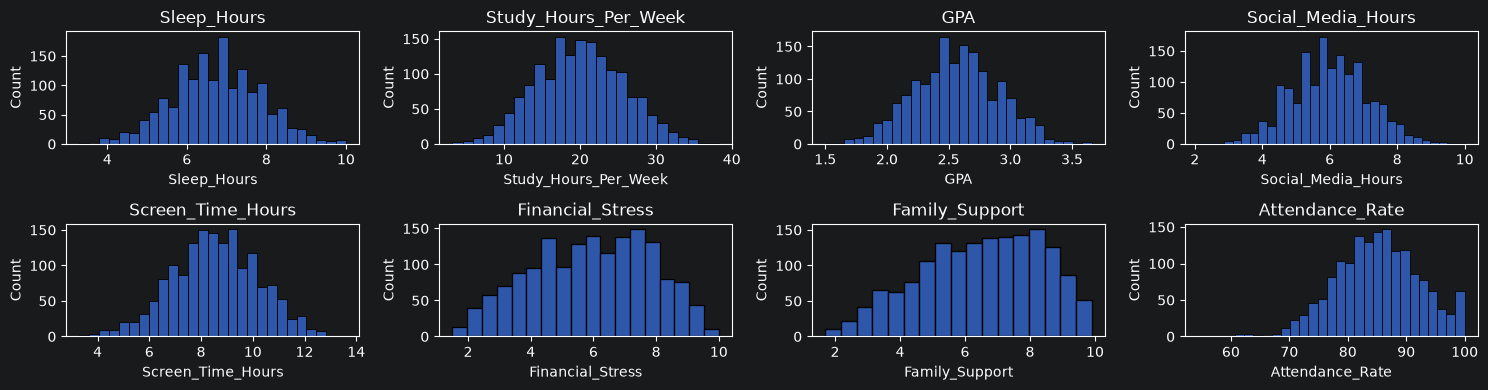

In [24]:
draw_quant_continous(df)

In [25]:
def draw_quant_discret(df):
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 4))
    col = 0
    for column in df[quantitative["discrete"]].columns:
        sns.histplot(data=df[column], ax=axes[col], discrete=True)
        axes[col].set_title(column)
        col += 1
    plt.tight_layout()
    plt.show()

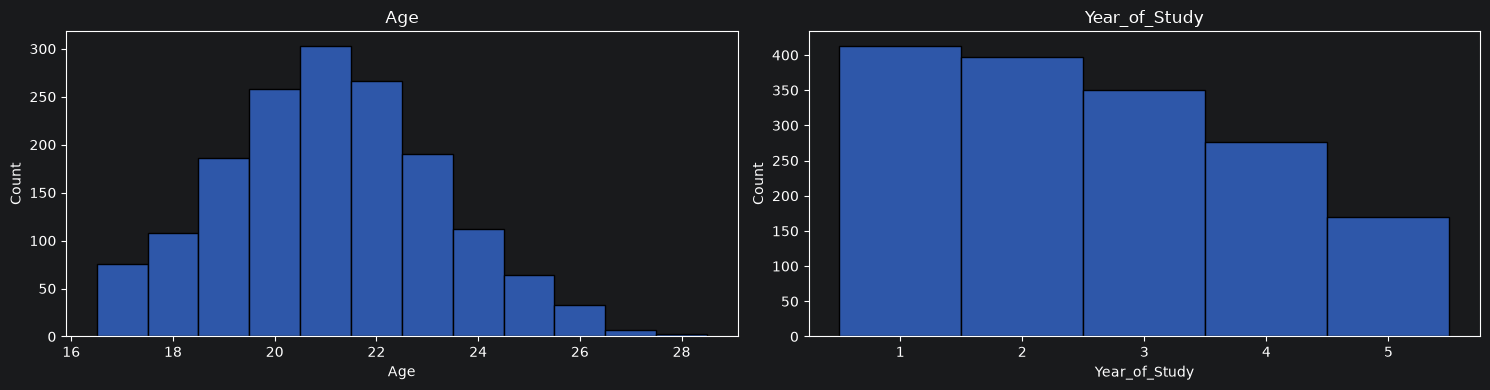

In [26]:
draw_quant_discret(df)

### Qualitative

In [27]:
def draw_qual_nominal(df):
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))
    col = 0
    for column in df[qualitative["nominal"]].columns:
        sns.countplot(data=df[column], ax=axes[col])
        axes[col].set_title(column)
        col += 1
    plt.tight_layout()
    plt.show()

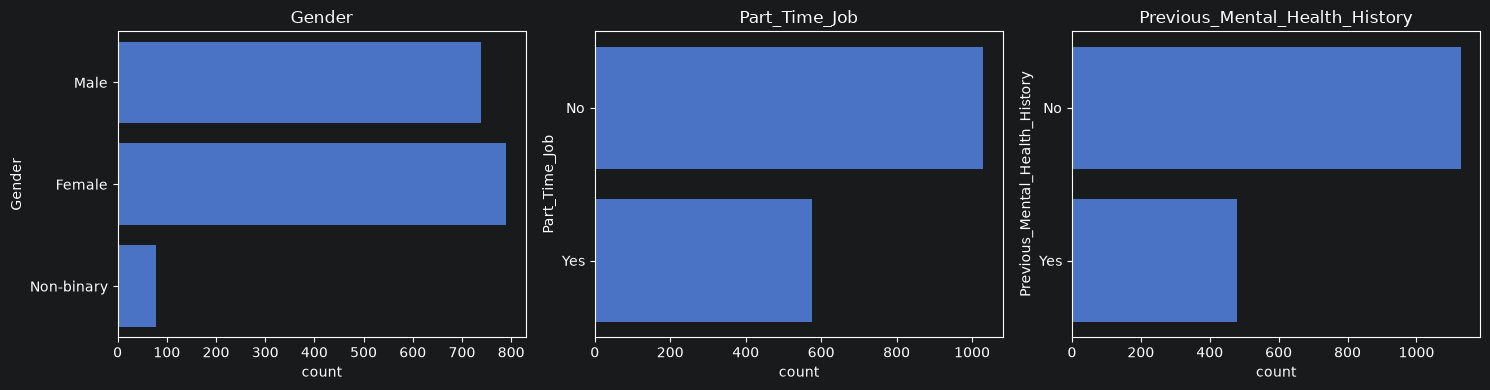

In [28]:
draw_qual_nominal(df)

In [45]:
def draw_qual_ordinal(df):
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))
    col = 0
    for column in df[qualitative["ordinal"]].columns:
        sns.countplot(data=df[column], ax=axes[col], order=qualitative["ordinal_order"][column])
        axes[col].set_title(column)
        col += 1
    plt.tight_layout()
    plt.show()

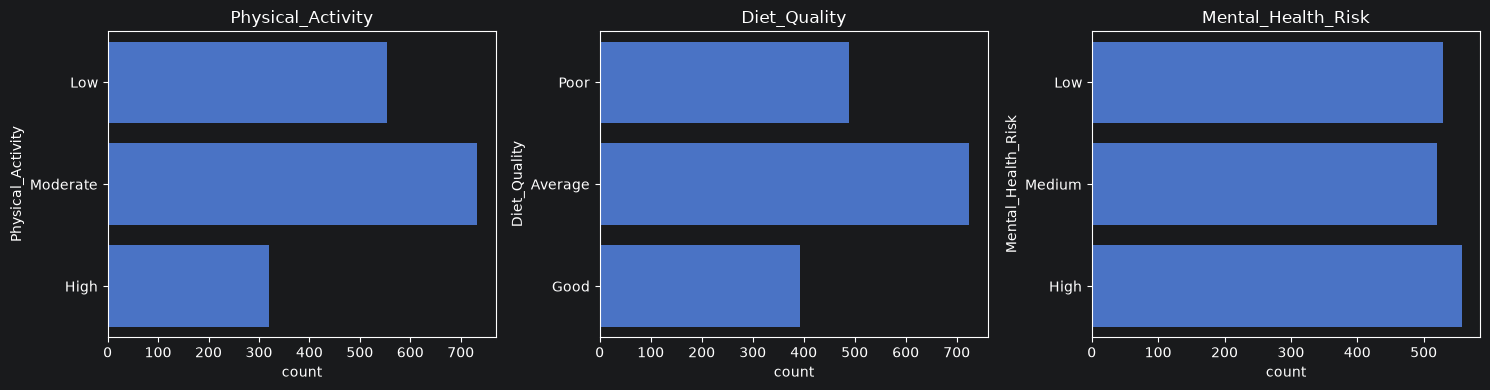

In [46]:
draw_qual_ordinal(df)